# Task 26 — Readmission risk after discharge: who gets the follow-up call

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [Diabetes 130-US hospitals for years 1999–2008](https://www.kaggle.com/datasets/brandao/diabetes) (101,766 diabetic inpatient encounters; Strack et al., 2014), plus the code tables of the [UCI original](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008)
**Task family:** tabular classification under a call capacity, grouped evaluation without dates, a small knowledge graph · **Companion task:** `02_card_fraud_tabular.ipynb` (the same discipline, with a clock)

---

## The task card

> **Board question.** *Our care-coordination nurses can make 25 follow-up calls a week against about 195 diabetic discharges, and roughly 1 in 9 of those patients is back in hospital within 30 days. Which 25 should they call, how many of the readmissions will those calls reach, and are the misses spread evenly across race, sex and age?*

**Business context.** A transitional-care team phones patients after discharge about medicines, follow-up appointments and whom to ring, on a fixed call budget. The score is computed when the discharge is recorded (Session 01's *online prediction*), from what the EHR holds then, and a nurse decides (*human-in-the-loop*). The legacy estate: the admit–discharge–transfer (ADT) feed, the coding department (ICD-9 codes, after discharge), pharmacy, the nurses' worklist. The score orders the worklist; it never withholds care.

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **readmission-risk model**, packaged and reproducible, scored at discharge, evaluated on unseen patients later in the order;
2. an **operating point set by call capacity**, with an error check by race, sex and age;
3. a small **knowledge base** (ICD-9 hierarchy, medication classes) with SHACL and an ablation;
4. the **operational wrapper**: package, CI gate on a frozen holdout, registry, model card, monitoring without a clock.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Scoring at discharge between ADT feed and worklist; health data, AI Act |
| 2 · MLOps | Grouped split on an ordering proxy, capacity gate, drift without a calendar |
| 3 · Semantic layer | ICD-9 hierarchy and medication classes; SHACL as a data gate |
| 4 · LLM/RAG | A nurse's call script grounded in the encounter, no clinical advice (Session 10) |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The notebook contains **deliberate traps**, each flagged with ⚠ in the text; turning each into a test is part of the task.

**Honesty note.** The data is **real**: de-identified Cerner Health Facts encounters (Strack et al., 2014), diabetic stays of 1–14 days, messy and undated. How the label was derived is not visible. Volumes, call budget and costs are assumptions.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card, first look and the evidence for the ordering proxy | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–6 | The knowledge base and features, evaluation on new patients, the 25-call operating point and fairness check, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 7–10 | Drift without a calendar, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 7 shows the signals your monitoring must carry. |

**What you need from Parts A and B**

- **Code to package:** `get_raw`, `get_ids_mapping` and `load_encounters` (Section 1); `destination` (Section 2); `norm_icd9`, `build_kb`, `shacl_violations` and `build_features` (Section 3); `fit`, `evaluate` and `precision_at_k` (Section 4); `prec_at_capacity_w`, `error_slices` and `readable` (Section 5); `psi` and `psi_cat` for monitoring (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** 69,609 training, 10,913 validation and 10,781 holdout encounters (new patients, split on the `encounter_id` order); holdout AUPRC 0.153 (lift 1.74) and ROC-AUC 0.637; at 25 calls a week, precision 16.5 % and recall 24.1 %, reaching 4.1 readmissions a week against 3.2 for the prior-stays rule; net value €4,199 a week at the assumed costs.
- **Runtime:** about 1–2 minutes on a laptop (73 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, io, json, time, hashlib, zipfile, warnings, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import sklearn
import rdflib
import pyshacl
from rdflib import Graph, Literal, Namespace, RDF, RDFS, XSD
from rdflib.namespace import SKOS
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.model_selection import train_test_split, GroupShuffleSplit

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20)

# ---- parameters -------------------------------------------------------------
SEED = 3217
KAGGLE_HANDLE = "brandao/diabetes"
UCI_ZIP = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"  # IDs_mapping.csv lives only here
TRAIN_END_Q, VALID_END_Q = 0.70, 0.85   # cut points on the encounter-order proxy (there are no dates; Section 2)
TARGET = "<30"                          # readmitted within 30 days; ">30" and "NO" are both negatives (Trap 3)
DISCHARGES_PER_WEEK = 195               # assumption: the dataset's own average, 101,766 encounters / 522 weeks
CALLS_PER_WEEK = 25                     # assumption: the care team's call budget (vary it in task C3)
CALL_COST_EUR = 30.0                    # assumption: ~20 nurse-minutes plus scheduling per call (C3)
READMISSION_COST_EUR = 12_000.0         # assumption: what one readmission costs the hospital or payer (C3)
CALL_EFFECT = 0.10                      # assumption: share of reached readmissions a call prevents; the evidence is mixed (C3)
N_BOOT = 200                            # patient-level bootstrap resamples for metric differences
N_JOBS = 1                              # threads per model: 1 on a shared machine, raise it on your laptop
LGB_PARAMS = dict(n_estimators=250, learning_rate=0.05, num_leaves=31, min_child_samples=100, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.8, reg_lambda=5.0, cat_l2=10, cat_smooth=20,
                  max_cat_to_onehot=8, min_data_per_group=50, random_state=SEED, n_jobs=N_JOBS, verbose=-1)
CALL_SHARE = CALLS_PER_WEEK / DISCHARGES_PER_WEEK

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "diabetes130", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
np.random.seed(SEED)
T_START = time.time()
print(f"pandas {pd.__version__} · lightgbm {lgb.__version__} · scikit-learn {sklearn.__version__} · numpy {np.__version__} · "
      f"rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")

pandas 3.1.0 · lightgbm 4.7.0 · scikit-learn 1.9.1 · numpy 2.5.4 · rdflib 7.6.0 · pyshacl 0.40.1


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw`, `get_ids_mapping` and `load_encounters` with the salted patient hash.*

| Field | Value |
|---|---|
| **Source** | Kaggle `brandao/diabetes`, repackaging UCI dataset 296 (doi:10.24432/C5230J; Strack et al., 2014) |
| **Licence** | CC0 on Kaggle; CC BY 4.0 at UCI: cite Strack et al. either way |
| **Provenance** | Real Cerner Health Facts encounters, HIPAA de-identified: inpatient, diabetes coded, 1–14 days. The years 1999–2008 come from the source; rows carry no dates |
| **Size** | 101,766 encounters, 71,518 patients, 50 columns, 19.2 MB |
| **Files** | `diabetic_data.csv`, `description.pdf` (the paper); `IDs_mapping.csv` (code tables) is **not on Kaggle**: the loader fetches it from UCI |
| **Schema** | keys, `race`, `gender`, `age` band, `weight`; coded admission type, source and discharge disposition; payer, specialty; stay and prior-year counts; `diag_1`–`diag_3` (ICD-9); two lab results; 23 medication columns |
| **Label** | `readmitted` ∈ {NO, >30, <30}: 54,864 / 35,545 / 11,357; the target is `<30` |
| **Window used here** | All of it, partitioned by `encounter_id` order (Section 2): 70 % train, 15 % validation, 15 % holdout |
| **PII** | No names or dates. The loader keeps only the *order* of `encounter_id`, hashes `patient_nbr` with a salt, drops `weight` (97 % missing). Race, gender and age serve only the fairness check |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **No dates.** A forward evaluation needs a proxy, and evidence for it.
2. ⚠ **Patients repeat.** A random split puts a person on both sides; a count over a patient's whole file sees their future.
3. ⚠ **Some patients cannot be readmitted.** 1,652 encounters end in death (dispositions 11, 19–21), 771 in hospice (13, 14).
4. ⚠ **Two kinds of missing.** `?` is unknown; `None` in the lab columns means *not measured*, and pandas reads it as NaN.
5. ⚠ **Diagnoses arrive after discharge.** `diag_1`–`diag_3` and `number_diagnoses` come from coding; the data has no coding date.
6. **The codes went through a number.** Leading zeros are lost (`38` is 038, septicaemia), trailing zeros too (`250.1` is 250.10, `250` is 250.00); apart from `365.44`, only diabetes codes keep decimals.
7. **"Unknown" has many spellings** (NULL, Not Mapped, Not Available, Unknown/Invalid).
8. **`examide` and `citoglipton` are empty**; neither is a drug name we can identify with confidence.

In [2]:
def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

def get_ids_mapping() -> Path:
    """IDs_mapping.csv is not in the Kaggle packaging; the UCI original ships it (as IDS_mapping.csv)."""
    local = RAW / "IDs_mapping.csv"
    if not local.exists():
        with urllib.request.urlopen(UCI_ZIP, timeout=120) as r, zipfile.ZipFile(io.BytesIO(r.read())) as z:
            local.write_bytes(z.read(next(n for n in z.namelist() if n.lower().endswith("ids_mapping.csv"))))
    return local

def read_id_tables(path: Path) -> dict:
    """The file stacks three two-column tables (admission type, discharge disposition, admission source)."""
    tables, current = {}, None
    for key, desc in pd.read_csv(path, header=None, dtype=str, keep_default_na=False).itertuples(index=False):
        key, desc = key.strip(), desc.strip()
        if key.endswith("_id"):
            current = key; tables[current] = {}
        elif key:
            tables[current][int(key)] = desc
    return tables

INT_COLS = ["encounter_id", "patient_nbr", "admission_type_id", "discharge_disposition_id", "admission_source_id",
            "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_outpatient",
            "number_emergency", "number_inpatient", "number_diagnoses"]
SALT = "ari3217-task26"   # in a real system the salt is a secret held outside Git

def load_encounters() -> pd.DataFrame:
    cache = PROCESSED / "26_encounters.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    # dtype=str and keep_default_na=False: '?' and 'None' stay exactly as written (Trap 5)
    df = pd.read_csv(get_raw("diabetic_data.csv"), dtype=str, keep_default_na=False)
    df[INT_COLS] = df[INT_COLS].astype(int)
    df = df.sort_values("encounter_id").reset_index(drop=True)
    # ---- governance on load: keep only the ORDER of encounter_id, pseudonymise the patient, drop weight ----
    df["order"] = (np.arange(len(df)) + 0.5) / len(df)
    df["patient"] = [hashlib.sha256(f"{SALT}{v}".encode()).hexdigest()[:16] for v in df.patient_nbr]
    df = df.drop(columns=["encounter_id", "patient_nbr", "weight"])
    df.to_parquet(cache)
    return df

df = load_encounters()
df["pid"] = pd.factorize(df.patient)[0]          # integer key: grouping on 16-character strings is slow
ids = read_id_tables(get_ids_mapping())
DISP, ADM_SRC, ADM_TYPE = ids["discharge_disposition_id"], ids["admission_source_id"], ids["admission_type_id"]
DEATH_IDS = sorted(k for k, v in DISP.items() if "expired" in v.lower())
HOSPICE_IDS = sorted(k for k, v in DISP.items() if "hospice" in v.lower() and k not in DEATH_IDS)
UNKNOWN_WORDS = {"NULL", "Not Mapped", "Not Available", "Unknown/Invalid"}

# protected attributes live in their own frame: used for the fairness check, never as features
protected = df[["race", "gender", "age"]].copy()
df["y"] = (df.readmitted == TARGET).astype(int)
df["eligible"] = ~df.discharge_disposition_id.isin(DEATH_IDS + HOSPICE_IDS)
raw_csv = get_raw("diabetic_data.csv")
print(f"diabetic_data.csv: {raw_csv.stat().st_size/1e6:.1f} MB, {len(pd.read_csv(raw_csv, nrows=0).columns)} columns")
print(f"{len(df):,} encounters · {df.pid.nunique():,} patients · readmitted {df.readmitted.value_counts().to_dict()} · "
      f"death {df.discharge_disposition_id.isin(DEATH_IDS).sum():,} (ids {DEATH_IDS}) · hospice "
      f"{df.discharge_disposition_id.isin(HOSPICE_IDS).sum():,} (ids {HOSPICE_IDS}) · {df.memory_usage(deep=True).sum()/1e6:.0f} MB")
df[["order", "patient", "admission_source_id", "discharge_disposition_id", "time_in_hospital", "number_inpatient",
    "diag_1", "diag_2", "diag_3", "A1Cresult", "insulin", "readmitted"]].head(3)

diabetic_data.csv: 19.2 MB, 50 columns
101,766 encounters · 71,518 patients · readmitted {'NO': 54864, '>30': 35545, '<30': 11357} · death 1,652 (ids [11, 19, 20, 21]) · hospice 771 (ids [13, 14]) · 54 MB


,order,patient,admission_source_id,discharge_disposition_id,time_in_hospital,number_inpatient,diag_1,diag_2,diag_3,A1Cresult,insulin,readmitted
0,0.000005,3878b2e97366d21b,4,1,13,0,398,427,38,None,Steady,NO
1,0.000015,a64367fa3dec0754,4,3,12,0,434,198,486,None,Steady,NO
2,0.000025,4ae1e4c127eb99a7,7,1,1,0,197,157,250,None,Steady,NO


## 2 · First look: who can be readmitted, who comes back, and what stands in for a clock

*Part A · Explore · read; the evidence for the ordering proxy becomes C1's ADR.*

,n,readmit_30d,rate
destination,,,
died,"1,652",0,0.0%
hospice,771,43,5.6%
home,"60,234","5,602",9.3%
not recorded,"4,680",551,11.8%
home with services,"13,010","1,653",12.7%
left against advice,623,90,14.4%
another facility or hospital,"20,796","3,418",16.4%


patients with 2+ encounters: 16,773 (47,021 encounters, max 40) · 30-day rate by prior-year stays 0 → 5+: 8.4% → 36.4%


,'?' (unknown),'None' (test not done)
race,2.2%,0.0%
payer_code,39.6%,0.0%
medical_specialty,49.1%,0.0%
diag_1,0.0%,0.0%
diag_2,0.4%,0.0%
diag_3,1.4%,0.0%
max_glu_serum,0.0%,94.7%
A1Cresult,0.0%,83.3%


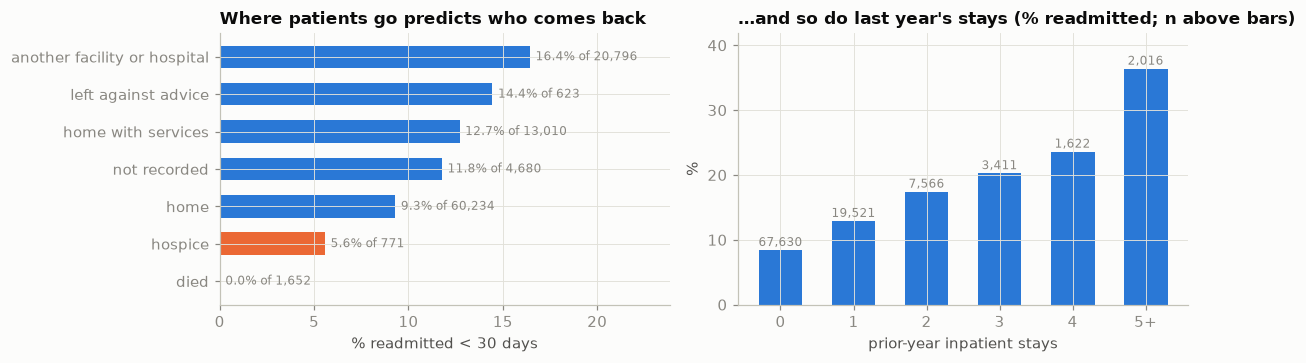

In [3]:
def destination(i: int) -> str:
    d = DISP.get(i, "Unknown/Invalid")
    if i in DEATH_IDS: return "died"
    if i in HOSPICE_IDS: return "hospice"
    if d in UNKNOWN_WORDS: return "not recorded"
    if d == "Left AMA": return "left against advice"
    if d == "Discharged to home": return "home"
    if "to home" in d: return "home with services"
    return "another facility or hospital"

df["destination"] = df.discharge_disposition_id.map(destination)
dest = (df.groupby("destination").agg(n=("y", "size"), readmit_30d=("y", "sum"), rate=("y", "mean"))
          .sort_values("rate"))
inp = df.assign(prior_year_stays=df.number_inpatient.clip(upper=5)).groupby("prior_year_stays").agg(n=("y", "size"), rate=("y", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
ax.barh(dest.index, dest.rate * 100, color=[SERIES[1] if i in ("died", "hospice") else SERIES[0] for i in dest.index], height=0.6)
for j, (r, n) in enumerate(zip(dest.rate, dest.n)):
    ax.text(r * 100 + 0.3, j, f"{r:.1%} of {n:,}", va="center", fontsize=8, color=MUTED)
ax.set_xlim(0, dest.rate.max() * 100 * 1.45)
ax.set_title("Where patients go predicts who comes back"); ax.set_xlabel("% readmitted < 30 days")
ax = axes[1]
ax.bar([str(i) if i < 5 else "5+" for i in inp.index], inp.rate * 100, color=SERIES[0], width=0.6)
for j, (r, n) in enumerate(zip(inp.rate, inp.n)):
    ax.text(j, r * 100 + 0.6, f"{n:,}", ha="center", fontsize=8, color=MUTED)
ax.set_ylim(0, inp.rate.max() * 100 * 1.15)
ax.set_title("…and so do last year's stays (% readmitted; n above bars)"); ax.set_xlabel("prior-year inpatient stays"); ax.set_ylabel("%")
plt.tight_layout()
display(dest.style.format({"n": "{:,}", "readmit_30d": "{:,}", "rate": "{:.1%}"}))
per_patient = df.groupby("pid").size()
print(f"patients with 2+ encounters: {(per_patient > 1).sum():,} ({per_patient[per_patient > 1].sum():,} encounters, max {per_patient.max()}) · "
      f"30-day rate by prior-year stays 0 → 5+: {inp.rate.iloc[0]:.1%} → {inp.rate.iloc[-1]:.1%}")

placeholders = pd.DataFrame({
    "'?' (unknown)": {c: (df[c] == "?").mean() for c in ["race", "payer_code", "medical_specialty", "diag_1", "diag_2", "diag_3"]},
    "'None' (test not done)": {c: (df[c] == "None").mean() for c in ["max_glu_serum", "A1Cresult"]},
}).fillna(0)
display(placeholders.style.format("{:.1%}"))

Destination matters most: 16.4 % of patients sent to another facility or hospital are back within 30 days, 9.3 % of those sent home, none who died. The rate climbs from 8.4 % with no inpatient stay in the prior year to 36.4 % with five or more. The placeholder table is Trap 5 in waiting.

**There are no dates.** `encounter_id` is the only candidate order, and nothing documents it as chronological. If it were, later encounters should follow readmission labels, prior-year inpatient counts should rise, and drugs should come and go when the market says. The next cell tests all three.

share of encounters with a later encounter of the same patient, by label:


readmitted,<30,>30,NO
has a later encounter,71.6%,60.8%,0.9%


consecutive encounters of a patient: prior-year inpatient count rises 73.7%, stays 16.4%, falls 9.9%
troglitazone (withdrawn from the US market in March 2000): 3 encounters, all in the first 0.12% of the order
Strack et al.'s population rebuilt (first encounter per patient, no death or hospice): 69,973


,readmit_30d,rosiglitazone,pioglitazone,payer_unknown,specialty_unknown,source_unrecorded
decile,,,,,,
0,10.9%,6.0%,3.7%,100.0%,36.4%,14.0%
1,12.0%,6.4%,5.1%,100.0%,43.1%,16.6%
2,11.8%,6.7%,6.6%,65.6%,34.4%,18.1%
3,10.8%,7.6%,7.4%,26.6%,21.2%,12.0%
4,11.9%,7.9%,7.7%,30.9%,44.2%,1.8%
5,11.2%,7.6%,7.6%,29.0%,53.7%,0.8%
6,10.8%,7.5%,8.6%,12.7%,57.5%,1.5%
7,10.9%,7.4%,8.5%,6.6%,65.1%,1.4%
8,10.7%,3.2%,8.8%,10.5%,67.3%,1.6%


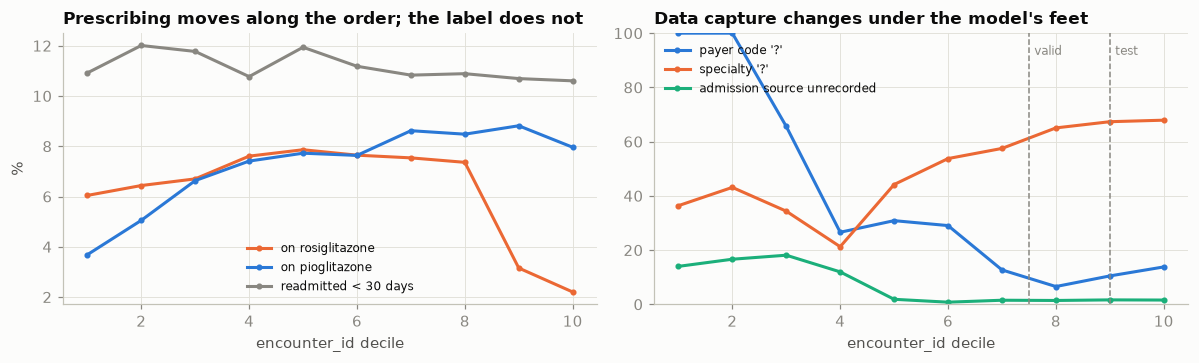

In [4]:
# Evidence that encounter_id order behaves like time (we never treat it as a calendar)
g = df.groupby("pid", sort=False)
df["prior_enc"] = g.cumcount()                                   # this patient's earlier encounters, in id order
has_next = g.cumcount(ascending=False) > 0
evidence = pd.crosstab(df.readmitted, has_next, normalize="index").rename(columns={True: "has a later encounter", False: "last seen"})
evidence.columns.name, evidence.index.name = None, "readmitted"
nxt = g.number_inpatient.shift(-1)
step = (nxt - df.number_inpatient)[nxt.notna()]
print("share of encounters with a later encounter of the same patient, by label:")
display(evidence[["has a later encounter"]].T.style.format("{:.1%}"))
print(f"consecutive encounters of a patient: prior-year inpatient count rises {(step > 0).mean():.1%}, "
      f"stays {(step == 0).mean():.1%}, falls {(step < 0).mean():.1%}")
trog = df.order[df.troglitazone != "No"]
print(f"troglitazone (withdrawn from the US market in March 2000): {len(trog)} encounters, all in the first "
      f"{trog.max():.2%} of the order")
print(f"Strack et al.'s population rebuilt (first encounter per patient, no death or hospice): {(df.eligible & (df.prior_enc == 0)).sum():,}")

df["decile"] = (df.order * 10).astype(int)
dec = df.groupby("decile").agg(
    readmit_30d=("y", "mean"),
    rosiglitazone=("rosiglitazone", lambda s: (s != "No").mean()),
    pioglitazone=("pioglitazone", lambda s: (s != "No").mean()),
    payer_unknown=("payer_code", lambda s: (s == "?").mean()),
    specialty_unknown=("medical_specialty", lambda s: (s == "?").mean()),
    source_unrecorded=("admission_source_id", lambda s: s.map(ADM_SRC).isin(UNKNOWN_WORDS).mean()),
)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
for col, lab_, c in [("rosiglitazone", "on rosiglitazone", SERIES[1]), ("pioglitazone", "on pioglitazone", SERIES[0]),
                     ("readmit_30d", "readmitted < 30 days", MUTED)]:
    ax.plot(dec.index + 1, dec[col] * 100, "-o", ms=3, lw=2, color=c, label=lab_)
ax.set_title("Prescribing moves along the order; the label does not"); ax.set_xlabel("encounter_id decile"); ax.set_ylabel("%")
ax.legend(fontsize=8)
ax = axes[1]
for col, lab_, c in [("payer_unknown", "payer code '?'", SERIES[0]), ("specialty_unknown", "specialty '?'", SERIES[1]),
                     ("source_unrecorded", "admission source unrecorded", SERIES[2])]:
    ax.plot(dec.index + 1, dec[col] * 100, "-o", ms=3, lw=2, color=c, label=lab_)
ax.axvline(TRAIN_END_Q * 10 + 0.5, color=MUTED, ls="--", lw=1); ax.axvline(VALID_END_Q * 10 + 0.5, color=MUTED, ls="--", lw=1)
ax.text(TRAIN_END_Q * 10 + 0.6, 92, "valid", color=MUTED, fontsize=8); ax.text(VALID_END_Q * 10 + 0.6, 92, "test", color=MUTED, fontsize=8)
ax.set_ylim(0, 100); ax.set_title("Data capture changes under the model's feet"); ax.set_xlabel("encounter_id decile"); ax.legend(fontsize=8)
plt.tight_layout()
dec.style.format("{:.1%}")

All three hold. After an encounter labelled `NO` the same patient appears again 0.9 % of the time, after `<30` 71.6 %; the prior-year inpatient count rises between consecutive encounters 73.7 % of the time and falls 9.9 %. Troglitazone (withdrawn in the US in March 2000) appears only in the first 0.12 % of the order; rosiglitazone falls from 7.9 % to 2.2 % in the last decile, fitting the 2007 safety concerns (Nissen and Wolski, 2007). The paper's population rebuilds to 69,973 encounters (paper: 69,984).

Our reading, for an ADR: **`encounter_id` order is a proxy for time, not a calendar.** Its scale is unknown and ids may be allocated per hospital, so we use it for order only: to split, to count a patient's history, and to look for drift. The right panel shows that drift, in recording rather than patients: payer unknown for the whole first fifth and 13.8 % of the last decile, specialty unknown from 36 % to 68 %, while the 30-day rate stays within 10.6–12.0 %.

# Part B — The given model

*Sections 3–6: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · A small knowledge base: the ICD-9 hierarchy and the medication classes

*Part B · Given model · package `norm_icd9`, `build_kb`, `shacl_violations` and `build_features` unchanged; E1 extends this knowledge base.*

The model sees 717 primary-diagnosis strings; nurses think in chapters, conditions and drug classes. Three competency questions (Session 07) define the KB:

- **CQ1.** Which ICD-9 chapter and which analytic group (Strack et al.) does a code belong to?
- **CQ2.** Which complication, type and control does a diabetes code record?
- **CQ3.** Which therapeutic class is each medication column?

The pipeline normalises each code into code → category → chapter; SHACL (Session 08) checks every code; SPARQL (Session 09) turns answers into lookup tables.

In [5]:
RD = Namespace("https://ari3217.example/readmit#")

# ICD-9-CM chapters (CDC/NCHS tabular list): numeric range → chapter
CHAPTERS = [(1, 139, "infectious", "Infectious and parasitic diseases"), (140, 239, "neoplasms", "Neoplasms"),
            (240, 279, "endocrine", "Endocrine, nutritional and metabolic diseases, and immunity disorders"),
            (280, 289, "blood", "Diseases of the blood and blood-forming organs"), (290, 319, "mental", "Mental disorders"),
            (320, 389, "nervous", "Diseases of the nervous system and sense organs"),
            (390, 459, "circulatory", "Diseases of the circulatory system"), (460, 519, "respiratory", "Diseases of the respiratory system"),
            (520, 579, "digestive", "Diseases of the digestive system"), (580, 629, "genitourinary", "Diseases of the genitourinary system"),
            (630, 679, "pregnancy", "Complications of pregnancy, childbirth and the puerperium"),
            (680, 709, "skin", "Diseases of the skin and subcutaneous tissue"),
            (710, 739, "musculoskeletal", "Diseases of the musculoskeletal system and connective tissue"),
            (740, 759, "congenital", "Congenital anomalies"), (760, 779, "perinatal", "Certain conditions originating in the perinatal period"),
            (780, 799, "symptoms", "Symptoms, signs and ill-defined conditions"), (800, 999, "injury", "Injury and poisoning")]
CHAPTER_LABEL = {c: l for _, _, c, l in CHAPTERS} | {"V": "Factors influencing health status (V codes)",
                                                     "E": "External causes of injury (E codes)"}
# the nine analytic groups of Strack et al. (2014, Table 2): symptom codes 785–788 are filed with their organ system
STRACK = [("circulatory", [(390, 459), (785, 785)]), ("respiratory", [(460, 519), (786, 786)]),
          ("digestive", [(520, 579), (787, 787)]), ("injury", [(800, 999)]), ("musculoskeletal", [(710, 739)]),
          ("genitourinary", [(580, 629), (788, 788)]), ("neoplasms", [(140, 239)])]
DM_COMPLICATION = {"0": "none stated", "1": "ketoacidosis", "2": "hyperosmolarity", "3": "other coma", "4": "renal",
                   "5": "ophthalmic", "6": "neurological", "7": "peripheral circulatory", "8": "other specified",
                   "9": "unspecified"}
# labels for the most frequent 3-digit categories, for people and for the call-script context (not used by the model)
CATEGORY_LABEL = {"428": "heart failure", "414": "other chronic ischaemic heart disease", "786": "respiratory and chest symptoms",
                  "410": "acute myocardial infarction", "486": "pneumonia, organism unspecified", "427": "cardiac dysrhythmias",
                  "491": "chronic bronchitis", "715": "osteoarthrosis", "682": "other cellulitis and abscess",
                  "434": "occlusion of cerebral arteries", "780": "general symptoms", "996": "complications of specified procedures",
                  "276": "fluid, electrolyte and acid-base disorders", "038": "septicaemia", "250": "diabetes mellitus",
                  "599": "other disorders of the urinary tract", "584": "acute kidney failure", "401": "essential hypertension",
                  "403": "hypertensive chronic kidney disease", "585": "chronic kidney disease"}
# medication columns → therapeutic class (combinations belong to both); two columns we cannot place with confidence
MED_CLASS = {"metformin": ["biguanide"], "repaglinide": ["meglitinide"], "nateglinide": ["meglitinide"],
             "chlorpropamide": ["sulfonylurea"], "glimepiride": ["sulfonylurea"], "acetohexamide": ["sulfonylurea"],
             "glipizide": ["sulfonylurea"], "glyburide": ["sulfonylurea"], "tolbutamide": ["sulfonylurea"],
             "tolazamide": ["sulfonylurea"], "pioglitazone": ["thiazolidinedione"], "rosiglitazone": ["thiazolidinedione"],
             "troglitazone": ["thiazolidinedione"], "acarbose": ["alpha_glucosidase_inhibitor"],
             "miglitol": ["alpha_glucosidase_inhibitor"], "insulin": ["insulin"],
             "glyburide-metformin": ["sulfonylurea", "biguanide"], "glipizide-metformin": ["sulfonylurea", "biguanide"],
             "glimepiride-pioglitazone": ["sulfonylurea", "thiazolidinedione"],
             "metformin-rosiglitazone": ["biguanide", "thiazolidinedione"],
             "metformin-pioglitazone": ["biguanide", "thiazolidinedione"],
             "examide": [], "citoglipton": []}
MEDS = list(MED_CLASS)

def norm_icd9(code: str):
    """Undo the numeric mangling upstream: 38 → 038, 250.1 → 250.10, 250 → 250.00. '?' → None."""
    if code in ("?", ""):
        return None
    if code[0] in "VE":
        return code
    head, _, tail = code.partition(".")
    head = head.zfill(3)
    if head == "250":
        return f"250.{(tail or '0').ljust(2, '0')}"
    return head + (f".{tail}" if tail else "")

def chapter_of(code: str) -> str:
    if code[0] in "VE":
        return code[0]
    n = int(code[:3])
    return next(c for lo, hi, c, _ in CHAPTERS if lo <= n <= hi)

def group_of(code: str) -> str:
    if code.startswith("250"):
        return "diabetes"
    if code[0] in "VE":
        return "other"
    n = int(code[:3])
    return next((gname for gname, ranges in STRACK if any(lo <= n <= hi for lo, hi in ranges)), "other")

def build_kb(codes, notation=lambda c: c) -> Graph:
    kb = Graph(); kb.bind("rd", RD); kb.bind("skos", SKOS)
    for ch, label in CHAPTER_LABEL.items():
        kb.add((RD[f"chapter/{ch}"], RDF.type, RD.Chapter)); kb.add((RD[f"chapter/{ch}"], RDFS.label, Literal(label)))
    for gname in [s[0] for s in STRACK] + ["diabetes", "other"]:
        kb.add((RD[f"group/{gname}"], RDF.type, RD.AnalyticGroup))
    for code in codes:
        c, cat = RD[f"code/{code}"], code[:4] if code[0] == "E" else code[:3]
        kb.add((c, RDF.type, RD.Code)); kb.add((c, RD.notation, Literal(notation(code))))
        kb.add((c, SKOS.broader, RD[f"category/{cat}"])); kb.add((RD[f"category/{cat}"], RDF.type, RD.Category))
        kb.add((RD[f"category/{cat}"], SKOS.broader, RD[f"chapter/{chapter_of(code)}"]))
        if cat in CATEGORY_LABEL:
            kb.add((RD[f"category/{cat}"], RDFS.label, Literal(CATEGORY_LABEL[cat])))
        kb.add((c, RD.inGroup, RD[f"group/{group_of(code)}"]))
        if code.startswith("250."):
            kb.add((c, RDF.type, RD.DiabetesCode))
            kb.add((c, RD.complication, Literal(DM_COMPLICATION[code[4]])))
            kb.add((c, RD.type1, Literal(code[5] in "13", datatype=XSD.boolean)))
            kb.add((c, RD.uncontrolled, Literal(code[5] in "23", datatype=XSD.boolean)))
    for med, classes in MED_CLASS.items():
        kb.add((RD[f"med/{med}"], RDF.type, RD.Medication)); kb.add((RD[f"med/{med}"], RDFS.label, Literal(med)))
        for cl in classes:
            kb.add((RD[f"med/{med}"], RD.memberOf, RD[f"class/{cl}"])); kb.add((RD[f"class/{cl}"], RDF.type, RD.MedicationClass))
    return kb

SHAPES = """
@prefix sh: <http://www.w3.org/ns/shacl#> . @prefix rd: <https://ari3217.example/readmit#> .
@prefix skos: <http://www.w3.org/2004/02/skos/core#> . @prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
rd:CodeShape a sh:NodeShape ; sh:targetClass rd:Code ;
  sh:property [ sh:path rd:notation ; sh:minCount 1 ; sh:maxCount 1 ;
                sh:pattern "^([0-9]{3}(\\\\.[0-9]{1,2})?|V[0-9]{2}(\\\\.[0-9]{1,2})?|E[0-9]{3}(\\\\.[0-9])?)$" ;
                sh:message "not a well-formed ICD-9-CM code" ] ;
  sh:property [ sh:path skos:broader ; sh:class rd:Category ; sh:minCount 1 ; sh:maxCount 1 ; sh:message "code has no category" ] ;
  sh:property [ sh:path rd:inGroup ; sh:class rd:AnalyticGroup ; sh:minCount 1 ; sh:maxCount 1 ; sh:message "code has no analytic group" ] .
rd:CategoryShape a sh:NodeShape ; sh:targetClass rd:Category ;
  sh:property [ sh:path skos:broader ; sh:class rd:Chapter ; sh:minCount 1 ; sh:maxCount 1 ; sh:message "category outside every chapter" ] .
rd:DiabetesShape a sh:NodeShape ; sh:targetClass rd:DiabetesCode ;
  sh:property [ sh:path rd:complication ; sh:minCount 1 ; sh:maxCount 1 ; sh:message "diabetes code without a 4th digit" ] ;
  sh:property [ sh:path rd:type1 ; sh:datatype xsd:boolean ; sh:minCount 1 ; sh:maxCount 1 ; sh:message "diabetes type not coded" ] .
rd:MedicationShape a sh:NodeShape ; sh:targetClass rd:Medication ;
  sh:property [ sh:path rd:memberOf ; sh:class rd:MedicationClass ; sh:minCount 1 ; sh:message "medication has no therapeutic class" ] .
"""
SH = Namespace("http://www.w3.org/ns/shacl#")
SHAPES_G = Graph().parse(data=SHAPES, format="turtle")

def shacl_violations(kb: Graph) -> pd.Series:
    _, report, _ = pyshacl.validate(kb, shacl_graph=SHAPES_G)
    msgs = [str(report.value(r, SH.resultMessage)) for r in report.subjects(RDF.type, SH.ValidationResult)]
    return pd.Series(msgs, dtype=object).value_counts()

for i in (1, 2, 3):
    df[f"code_{i}"] = df[f"diag_{i}"].map(norm_icd9)
codes = sorted(set(pd.concat([df.code_1, df.code_2, df.code_3]).dropna()))
raw_of = {}
for i in (1, 2, 3):
    raw_of.update(dict(zip(df[f"code_{i}"].dropna(), df.loc[df[f"code_{i}"].notna(), f"diag_{i}"])))

kb_naive = build_kb(codes, notation=lambda c: raw_of[c])    # the same graph, but notations as the CSV spells them
kb = build_kb(codes)
print(f"knowledge base: {len(kb):,} triples · {len(codes)} codes · {len(set(kb.subjects(RDF.type, RD.Category)))} categories · "
      f"{len(CHAPTER_LABEL)} chapters · {len(set(kb.subjects(RDF.type, RD.AnalyticGroup)))} analytic groups · "
      f"{len(MEDS)} medication columns in {len(set(kb.subjects(RDF.type, RD.MedicationClass)))} classes")
print("SHACL on notations as the CSV spells them:"); print(shacl_violations(kb_naive).to_string())
print("SHACL on the normalised knowledge base:"); print(shacl_violations(kb).to_string())

# CQ1–CQ3 answered with SPARQL; the answers become the lookup tables the features use
CQ1 = """SELECT ?code ?chapter ?group WHERE { ?c a rd:Code ; rd:notation ?code ; skos:broader/skos:broader ?ch ; rd:inGroup ?g .
         BIND(STRAFTER(STR(?ch), "chapter/") AS ?chapter) BIND(STRAFTER(STR(?g), "group/") AS ?group) }"""
CQ2 = """SELECT ?code ?complication ?type1 ?uncontrolled WHERE { ?c a rd:DiabetesCode ; rd:notation ?code ;
         rd:complication ?complication ; rd:type1 ?type1 ; rd:uncontrolled ?uncontrolled }"""
CQ3 = """SELECT ?med ?cls WHERE { ?m a rd:Medication ; rdfs:label ?med . OPTIONAL { ?m rd:memberOf ?k .
         BIND(STRAFTER(STR(?k), "class/") AS ?cls) } }"""
q = lambda s: pd.DataFrame([[str(v) if v is not None else None for v in row] for row in kb.query(s, initNs={"rd": RD, "skos": SKOS, "rdfs": RDFS})])
cq1 = q(CQ1).set_axis(["code", "chapter", "group"], axis=1).set_index("code")
cq2 = q(CQ2).set_axis(["code", "complication", "type1", "uncontrolled"], axis=1).set_index("code")
cq3 = q(CQ3).set_axis(["med", "cls"], axis=1)
print(f"CQ1 {len(cq1)} codes placed · CQ2 {len(cq2)} diabetes codes decoded · CQ3 classes: "
      f"{cq3.dropna().groupby('cls').med.apply(list).to_dict()}")

knowledge base: 5,703 triples · 915 codes · 881 categories · 19 chapters · 9 analytic groups · 23 medication columns in 6 classes
SHACL on notations as the CSV spells them:


not a well-formed ICD-9-CM code        43
medication has no therapeutic class     2
SHACL on the normalised knowledge base:


medication has no therapeutic class    2


CQ1 915 codes placed · CQ2 34 diabetes codes decoded · CQ3 classes: {'alpha_glucosidase_inhibitor': ['acarbose', 'miglitol'], 'biguanide': ['metformin', 'glyburide-metformin', 'glipizide-metformin', 'metformin-rosiglitazone', 'metformin-pioglitazone'], 'insulin': ['insulin'], 'meglitinide': ['repaglinide', 'nateglinide'], 'sulfonylurea': ['chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'tolazamide', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone'], 'thiazolidinedione': ['pioglitazone', 'rosiglitazone', 'troglitazone', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']}


SHACL flags 43 malformed, zero-stripped codes as the CSV spells them, before grouping can misfile them (Trap 6); after normalisation only `examide` and `citoglipton` remain, recorded as unclassified.

Feature families follow **when each fact exists**. *At discharge*: the stay, the prior year, administrative codes with *unknown* merged, lab results, the patient's number of *earlier* encounters, and the KB's medication classes. *After coding*: the diagnoses as raw codes or through the KB (chapters, analytic group, chapter counts, diabetes complication, type and control), plus `number_diagnoses`. Race, sex and age are in none.

In [6]:
def unknown_to_one(series: pd.Series, table: dict) -> pd.Series:
    return series.map(lambda v: "unknown" if table.get(v, "NULL") in UNKNOWN_WORDS else str(v))

def build_features(df: pd.DataFrame, lookup=cq1, dm=cq2) -> pd.DataFrame:
    X = pd.DataFrame(index=df.index)
    # ---- base: the stay and the prior year, as the EHR knows them at discharge ----
    for c in ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_outpatient",
              "number_emergency", "number_inpatient", "number_diagnoses", "prior_enc"]:
        X[c] = df[c]
    X["admission_type"] = unknown_to_one(df.admission_type_id, ADM_TYPE)
    X["admission_source"] = unknown_to_one(df.admission_source_id, ADM_SRC)
    X["discharge_disposition"] = unknown_to_one(df.discharge_disposition_id, DISP)
    for c in ["max_glu_serum", "A1Cresult", "change", "diabetesMed", "medical_specialty"]:
        X[c] = df[c]
    # ---- raw: the codes as the CSV spells them ----
    for i in (1, 2, 3):
        X[f"diag_{i}"] = df[f"diag_{i}"]
    for m in MEDS:
        X[f"med_{m}"] = df[m]
    # ---- KB: the same facts, through the ontology ----
    for i in (1, 2, 3):
        X[f"chapter_{i}"] = df[f"code_{i}"].map(lookup.chapter).fillna("missing")
    X["group_1"] = df.code_1.map(lookup.group).fillna("missing")
    for ch in CHAPTER_LABEL:
        X[f"n_chapter_{ch}"] = sum((X[f"chapter_{i}"] == ch).astype(int) for i in (1, 2, 3))
    dm_code = df.code_1.where(df.code_1.isin(dm.index)).fillna(df.code_2.where(df.code_2.isin(dm.index))).fillna(
        df.code_3.where(df.code_3.isin(dm.index)))
    X["dm_complication"] = dm_code.map(dm.complication).fillna("no diabetes code")
    X["dm_type1"] = (dm_code.map(dm.type1) == "true").astype(int)
    X["dm_uncontrolled"] = (dm_code.map(dm.uncontrolled) == "true").astype(int)
    for cl in sorted({k for v in MED_CLASS.values() for k in v}):
        members = [m for m, ks in MED_CLASS.items() if cl in ks]
        X[f"class_{cl}_on"] = (df[members] != "No").any(axis=1).astype(int)
        X[f"class_{cl}_changed"] = df[members].isin(["Up", "Down"]).any(axis=1).astype(int)
    X["n_meds_on"] = (df[MEDS] != "No").sum(axis=1)
    X["n_meds_up"] = (df[MEDS] == "Up").sum(axis=1)
    X["n_meds_down"] = (df[MEDS] == "Down").sum(axis=1)
    for c in X.columns:
        if X[c].dtype == object or str(X[c].dtype).startswith("str"):
            X[c] = X[c].astype("category")
    return X

X = build_features(df)
# what the EHR holds when the discharge is recorded …
AT_DISCHARGE = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_outpatient",
                "number_emergency", "number_inpatient", "prior_enc", "admission_type", "admission_source",
                "discharge_disposition", "max_glu_serum", "A1Cresult", "change", "diabetesMed", "medical_specialty"]
MED_RAW = [f"med_{m}" for m in MEDS]
MED_KB = [c for c in X.columns if c.startswith(("class_", "n_meds_"))]
# … and what exists only after the coding department has coded the stay
DX_RAW = ["number_diagnoses"] + [f"diag_{i}" for i in (1, 2, 3)]
DX_KB = ["number_diagnoses"] + [c for c in X.columns if c.startswith(("chapter_", "group_", "n_chapter_", "dm_"))]
KB = MED_KB + DX_KB[1:]
print(f"{X.shape[1]} features: at discharge {len(AT_DISCHARGE)} · medications raw {len(MED_RAW)} / KB classes {len(MED_KB)} · "
      f"after coding raw {len(DX_RAW)} / KB {len(DX_KB)} · diag_1 levels raw {X.diag_1.nunique()} → chapters {X.chapter_1.nunique()}")

84 features: at discharge 16 · medications raw 23 / KB classes 15 · after coding raw 4 / KB 27 · diag_1 levels raw 717 → chapters 19


## 4 · Honest evaluation: new patients, later in the order

*Part B · Given model · package `fit`, `evaluate` and `precision_at_k` unchanged and reproduce the holdout numbers (C2).*

A patient belongs to the period in which we first meet them: first seen in the first 70 % of the order means training, the next 15 % validation, the last 15 % the **holdout**, frozen for the CI gate. An encounter is used only inside its patient's own period, so no patient crosses a boundary and no training row comes later than a holdout row; returning patients' later encounters are scored separately.

Metrics: **AUPRC** with its **lift** (÷ base rate, comparable across populations) and **precision and recall at capacity** (25 calls per 195 discharges, 12.8 % of the holdout). Feature sets are compared on **validation** with a patient-level bootstrap, and the champion chosen there by a rule fixed in advance: only discharge-time sets qualify, and the richer wins only if its gain's interval is above zero. The holdout is scored once.

In [7]:
first_order = df.groupby("pid").order.transform("min")
period = np.select([df.order < TRAIN_END_Q, df.order < VALID_END_Q], ["train", "valid"], "test")
first_period = np.select([first_order < TRAIN_END_Q, first_order < VALID_END_Q], ["train", "valid"], "test")
df["part"] = np.where(period == first_period, period, "returning")
tr, va, te = [(df.part == p) & df.eligible for p in ("train", "valid", "test")]
ret_va = (period == "valid") & (df.part == "returning") & df.eligible
ret_te = (period == "test") & (df.part == "returning") & df.eligible
y = df.y
y_tr, y_va, y_te = y[tr].values, y[va].values, y[te].values
K_TEST = int(round(CALL_SHARE * te.sum()))
parts = pd.DataFrame({p: {"encounters": int(m.sum()), "patients": df.pid[m].nunique(), "readmit_30d": int(y[m].sum()),
                          "base rate": y[m].mean()} for p, m in
                      [("train", tr), ("valid", va), ("test (the frozen holdout)", te),
                       ("set aside: returning patients, valid period", ret_va),
                       ("set aside: returning patients, test period", ret_te)]}).T
display(parts.style.format({"encounters": "{:,.0f}", "patients": "{:,.0f}", "readmit_30d": "{:,.0f}", "base rate": "{:.1%}"}))
print(f"test = {te.sum():,} discharges ≈ {te.sum()/DISCHARGES_PER_WEEK:.0f} weeks of the team's volume → capacity k = {K_TEST:,} calls "
      f"({CALL_SHARE:.1%} of discharges)")

def precision_at_k(y_true, score, k):
    top = np.argsort(-np.asarray(score), kind="stable")[:k]
    yv = np.asarray(y_true)
    return yv[top].mean(), yv[top].sum() / yv.sum()

def fit(cols, mask=tr, target=None):
    target = y if target is None else target
    return lgb.LGBMClassifier(**LGB_PARAMS).fit(X.loc[mask, cols], target[mask])

def evaluate(name, y_true, p, k=None):
    k = int(round(CALL_SHARE * len(y_true))) if k is None else k
    pk, rk = precision_at_k(y_true, p, k)
    return {"model": name, "AUPRC": average_precision_score(y_true, p), "lift": average_precision_score(y_true, p) / np.mean(y_true),
            "ROC-AUC": roc_auc_score(y_true, p), "precision@capacity": pk, "recall@capacity": rk}

FMT = {"AUPRC": "{:.3f}", "lift": "{:.2f}", "ROC-AUC": "{:.3f}", "precision@capacity": "{:.1%}", "recall@capacity": "{:.1%}"}
LADDER = {"at discharge": AT_DISCHARGE,
          "at discharge + medication classes (KB)": AT_DISCHARGE + MED_KB,
          "after coding + raw codes": AT_DISCHARGE + MED_RAW + DX_RAW,
          "after coding + knowledge base": AT_DISCHARGE + MED_KB + DX_KB}
# every model is trained on the training patients and compared on VALIDATION; the holdout is not touched here
models, p_val, rows = {}, {}, []
for name, cols in LADDER.items():
    models[name] = fit(cols)
    p_val[name] = models[name].predict_proba(X.loc[va, cols])[:, 1]
    rows.append(evaluate(name, y_va, p_val[name]))
ladder = pd.DataFrame(rows).set_index("model")
display(ladder.style.format(FMT))

def boot_weights(pids, n=N_BOOT, seed=SEED):
    """Patient-level bootstrap weights: each resample redraws patients, so a patient's encounters move together."""
    r = np.random.default_rng(seed)
    idx = pd.factorize(pids)[0]; n_pat = idx.max() + 1
    return [r.multinomial(n_pat, np.full(n_pat, 1 / n_pat))[idx] for _ in range(n)]

W_VA = boot_weights(df.pid[va].values)
COMPARE = [("at discharge + medication classes (KB)", "at discharge"),
           ("after coding + knowledge base", "at discharge + medication classes (KB)"),
           ("after coding + knowledge base", "after coding + raw codes")]
boot = pd.DataFrame({f"{a}  −  {b}": np.percentile([average_precision_score(y_va, p_val[a], sample_weight=w) -
                                                     average_precision_score(y_va, p_val[b], sample_weight=w) for w in W_VA],
                                                    [2.5, 50, 97.5]) for a, b in COMPARE}, index=["2.5 %", "median", "97.5 %"]).T
display(boot.style.format("{:+.3f}"))

# the rule, fixed before looking: only the first two rows can score at discharge; take the richer one only if its
# validation gain is clear (interval above zero), otherwise the simpler one
CHOSEN = COMPARE[0][0] if boot.iloc[0]["2.5 %"] > 0 else COMPARE[0][1]
print(f"champion, chosen on validation: {CHOSEN}")

,encounters,patients,readmit_30d,base rate
train,"69,609","51,402","8,054",11.6%
valid,"10,913","9,230","1,009",9.2%
test (the frozen holdout),"10,781","9,355",945,8.8%
"set aside: returning patients, valid period","3,960","2,575",649,16.4%
"set aside: returning patients, test period","4,080","2,837",657,16.1%


test = 10,781 discharges ≈ 55 weeks of the team's volume → capacity k = 1,382 calls (12.8% of discharges)


,AUPRC,lift,ROC-AUC,precision@capacity,recall@capacity
model,,,,,
at discharge,0.162,1.75,0.639,18.7%,25.9%
at discharge + medication classes (KB),0.164,1.77,0.640,18.9%,26.3%
after coding + raw codes,0.164,1.77,0.640,18.6%,25.8%
after coding + knowledge base,0.172,1.86,0.652,19.4%,27.0%


,2.5 %,median,97.5 %
at discharge + medication classes (KB) − at discharge,-0.001,+0.003,+0.007
after coding + knowledge base − at discharge + medication classes (KB),-0.000,+0.009,+0.017
after coding + knowledge base − after coding + raw codes,-0.002,+0.009,+0.020


champion, chosen on validation: at discharge


holdout fingerprint (SHA-256 of 10,781 rows × 19 columns): 86c7d8ac388e6f54…


,AUPRC,lift,ROC-AUC,precision@capacity,recall@capacity
model,,,,,
holdout: new patients (at discharge),0.153,1.74,0.637,16.5%,24.1%
test-period returning patients,0.286,1.78,0.652,34.4%,27.4%


observed ÷ expected readmissions (1.00 = calibrated): {'validation': 0.85, 'test (holdout)': 0.85, 'test-period returning patients': 0.95}


top-5 features by gain (%): {'number_inpatient': 23.5, 'discharge_disposition': 17.2, 'num_lab_procedures': 11.9, 'medical_specialty': 11.2, 'num_medications': 8.1}


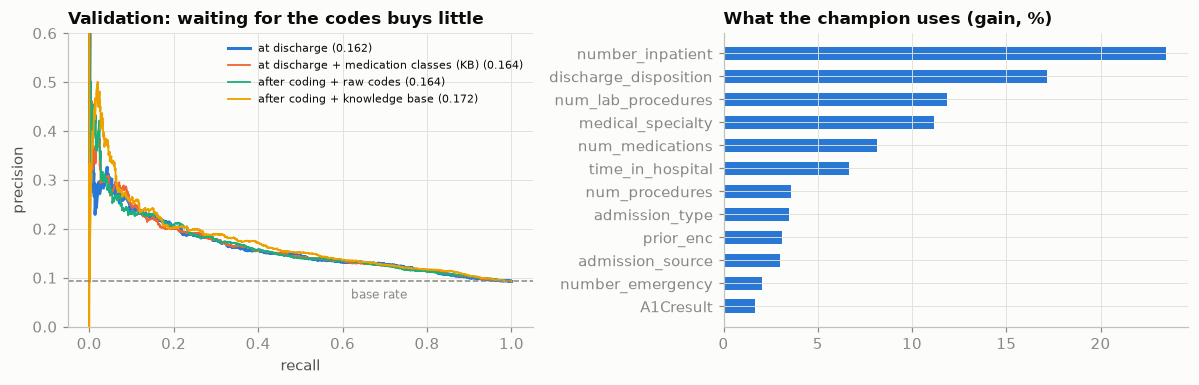

In [8]:
FEATS, m_chosen = LADDER[CHOSEN], models[CHOSEN]
p_va = p_val[CHOSEN]
# ---- the holdout, reported once ----
p_te = m_chosen.predict_proba(X.loc[te, FEATS])[:, 1]
p_ret = m_chosen.predict_proba(X.loc[ret_te, FEATS])[:, 1]
holdout_frame = pd.concat([df.loc[te, ["patient", "order", "readmitted"]], X.loc[te, FEATS]], axis=1)
HOLDOUT_SHA256 = hashlib.sha256(pd.util.hash_pandas_object(holdout_frame, index=False).values.tobytes()).hexdigest()
print(f"holdout fingerprint (SHA-256 of {len(holdout_frame):,} rows × {holdout_frame.shape[1]} columns): {HOLDOUT_SHA256[:16]}…")
display(pd.DataFrame([evaluate(f"holdout: new patients ({CHOSEN})", y_te, p_te),
                      evaluate("test-period returning patients", y[ret_te].values, p_ret)]).set_index("model").style.format(FMT))
calib = pd.Series({"validation": y_va.mean() / p_va.mean(), "test (holdout)": y_te.mean() / p_te.mean(),
                   "test-period returning patients": y[ret_te].mean() / p_ret.mean()})
print("observed ÷ expected readmissions (1.00 = calibrated):", calib.round(2).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
for (name, p), color in zip(p_val.items(), SERIES):
    pr, rc, _ = precision_recall_curve(y_va, p)
    ax.plot(rc, pr, lw=2 if name == CHOSEN else 1.2, color=color, label=f"{name} ({average_precision_score(y_va, p):.3f})")
ax.axhline(y_va.mean(), color=MUTED, ls="--", lw=1); ax.text(0.62, y_va.mean() * 0.62, "base rate", color=MUTED, fontsize=8)
ax.set_ylim(0, 0.6); ax.set_title("Validation: waiting for the codes buys little"); ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.legend(fontsize=7)
ax = axes[1]
gain = pd.Series(m_chosen.booster_.feature_importance("gain"), index=FEATS)
gain = (gain / gain.sum()).sort_values(ascending=False).head(12)
ax.barh(gain.index[::-1], gain.values[::-1] * 100, color=[SERIES[1] if f in KB else SERIES[0] for f in gain.index[::-1]], height=0.6)
ax.set_title("What the champion uses (gain, %)")
plt.tight_layout()
print("top-5 features by gain (%):", (gain.head(5) * 100).round(1).to_dict())

**Waiting for the codes buys little, and the call cannot wait.** On validation the at-discharge model reaches AUPRC 0.162; medication classes add +0.003 (−0.001 to +0.007), so the rule keeps the simpler set. Coded diagnoses through the KB would add +0.009 (−0.000 to +0.017), but only after coding, whose lag the data does not record; the KB beats raw codes by +0.009 (−0.002 to +0.020), not clearly. `number_inpatient` and the discharge disposition carry the champion.

**The holdout, once.** The champion scores AUPRC 0.153 (lift 1.74) and ROC-AUC 0.637 on new patients later in the order, typical of readmission models (Kansagara et al., 2011); its 1,382 calls are right 16.5 % of the time and reach 24.1 % of readmissions.

**Calibration is off by a sixth.** Observed ÷ expected is 0.85 on validation and holdout, 0.95 for returning patients (E2). Returning patients are easier to *find* (base rate 16.1 %, precision 34.4 %), not to *rank* (lift 1.78).

## 5 · The operating point: 25 calls a week

*Part B · Given model · package `prec_at_capacity_w`, `error_slices` and `readable`; C3 owns the quota, E3 the fairness check.*

Capacity binds, so the question is "which 25", not "which threshold". Three ways to fill 25 calls a week: the model, a rule nurses may already use (most inpatient stays last year), random calls. Values use the assumed constants (€30 a call, €12,000 a readmission, 10 % of reached readmissions prevented); vary them in C3.

,precision@capacity,recall@capacity,precision 95 % CI,readmissions reached / week,prevented / week (assumed effect),net value € / week,break-even call effect,"reached / week, 95 % CI"
model,,,,,,,,
model (champion),16.5%,24.1%,14.8%–18.6%,4.1,0.41,"4,199",1.5%,3.7–4.7
rule: most inpatient stays last year,12.7%,18.6%,11.1%–14.4%,3.2,0.32,"3,071",2.0%,2.8–3.6
random calls (expected),8.8%,12.8%,—,2.2,0.22,"1,880",2.9%,—


model − rule, precision at capacity: +3.8% (95 % CI +2.2% to +5.8%)


frozen threshold: 19.6 calls/week (min 9, max 29), 3.5 readmissions reached/week · weekly quota: 25 calls, 4.1 reached/week · 55 whole weeks


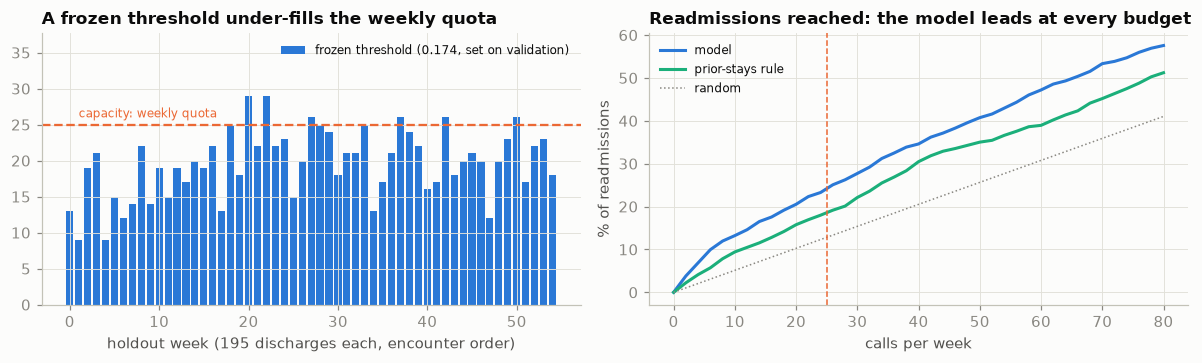

In [9]:
# three ways to fill the same 25 calls a week, ranked over the whole holdout
rng = np.random.default_rng(SEED)
rule = X.loc[te, "number_inpatient"].values + rng.random(te.sum()) * 1e-3     # the rule a care team may already use
op = pd.DataFrame([evaluate("model (champion)", y_te, p_te, K_TEST),
                   evaluate("rule: most inpatient stays last year", y_te, rule, K_TEST)]).set_index("model")[["precision@capacity", "recall@capacity"]]
op.loc["random calls (expected)"] = [y_te.mean(), K_TEST / te.sum()]

# patient-level bootstrap intervals for precision at capacity
W_TE = boot_weights(df.pid[te].values)
def prec_at_capacity_w(order, w):
    top = order[np.cumsum(w[order]) <= CALL_SHARE * w.sum()]
    return (w[top] * y_te[top]).sum() / w[top].sum()
o_model, o_rule = np.argsort(-p_te, kind="stable"), np.argsort(-rule, kind="stable")
b_model = np.array([prec_at_capacity_w(o_model, w) for w in W_TE])
b_rule = np.array([prec_at_capacity_w(o_rule, w) for w in W_TE])
ci = lambda a: np.percentile(a, [2.5, 97.5])
op["precision 95 % CI"] = [f"{lo:.1%}–{hi:.1%}" for lo, hi in (ci(b_model), ci(b_rule))] + ["—"]
op["readmissions reached / week"] = op["precision@capacity"] * CALLS_PER_WEEK
op["prevented / week (assumed effect)"] = op["readmissions reached / week"] * CALL_EFFECT
op["net value € / week"] = op["prevented / week (assumed effect)"] * READMISSION_COST_EUR - CALLS_PER_WEEK * CALL_COST_EUR
op["break-even call effect"] = CALL_COST_EUR / (op["precision@capacity"] * READMISSION_COST_EUR)
op["reached / week, 95 % CI"] = [f"{lo * CALLS_PER_WEEK:.1f}–{hi * CALLS_PER_WEEK:.1f}" for lo, hi in (ci(b_model), ci(b_rule))] + ["—"]
display(op.style.format({"precision@capacity": "{:.1%}", "recall@capacity": "{:.1%}", "readmissions reached / week": "{:.1f}",
                         "prevented / week (assumed effect)": "{:.2f}", "net value € / week": "{:,.0f}", "break-even call effect": "{:.1%}"}))
d_lo, d_hi = ci(b_model - b_rule)
print(f"model − rule, precision at capacity: {op.iloc[0, 0] - op.iloc[1, 0]:+.1%} (95 % CI {d_lo:+.1%} to {d_hi:+.1%})")

# the queue, week by week: a frozen threshold from validation against a weekly quota
THR = float(np.quantile(p_va, 1 - CALL_SHARE))
wk = pd.DataFrame({"week": np.arange(te.sum()) // DISCHARGES_PER_WEEK, "p": p_te, "y": y_te})
wk = wk[wk.groupby("week").week.transform("size") == DISCHARGES_PER_WEEK]       # whole weeks only
wk["call_thr"] = wk.p >= THR
wk["call_quota"] = wk.groupby("week").p.rank(ascending=False, method="first") <= CALLS_PER_WEEK
weekly = wk.groupby("week").agg(calls_thr=("call_thr", "sum"), calls_quota=("call_quota", "sum"),
                                hit_thr=("call_thr", lambda s: wk.y[s.index][s].sum()),
                                hit_quota=("call_quota", lambda s: wk.y[s.index][s].sum()), readmits=("y", "sum"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
ax.bar(weekly.index, weekly.calls_thr, color=SERIES[0], width=0.8, label=f"frozen threshold ({THR:.3f}, set on validation)")
ax.axhline(CALLS_PER_WEEK, color=SERIES[1], lw=1.5, ls="--"); ax.text(1, CALLS_PER_WEEK + 1, "capacity: weekly quota", color=SERIES[1], fontsize=8)
ax.set_ylim(0, max(weekly.calls_thr.max(), CALLS_PER_WEEK) * 1.3)
ax.set_title("A frozen threshold under-fills the weekly quota"); ax.set_xlabel("holdout week (195 discharges each, encounter order)"); ax.legend(fontsize=8, loc="upper right")
ax = axes[1]
calls = np.arange(0, 81, 2)
for s, lab_, c in [(p_te, "model", SERIES[0]), (rule, "prior-stays rule", SERIES[2])]:
    rec = [precision_at_k(y_te, s, int(round(cw / DISCHARGES_PER_WEEK * te.sum())))[1] if cw else 0 for cw in calls]
    ax.plot(calls, np.array(rec) * 100, lw=2, color=c, label=lab_)
ax.plot(calls, calls / DISCHARGES_PER_WEEK * 100, lw=1, ls=":", color=MUTED, label="random")
ax.axvline(CALLS_PER_WEEK, color=SERIES[1], ls="--", lw=1)
ax.set_title("Readmissions reached: the model leads at every budget"); ax.set_xlabel("calls per week"); ax.set_ylabel("% of readmissions"); ax.legend(fontsize=8)
plt.tight_layout()
print(f"frozen threshold: {weekly.calls_thr.mean():.1f} calls/week (min {weekly.calls_thr.min()}, max {weekly.calls_thr.max()}), "
      f"{weekly.hit_thr.mean():.1f} readmissions reached/week · weekly quota: {CALLS_PER_WEEK} calls, "
      f"{weekly.hit_quota.mean():.1f} reached/week · {len(weekly)} whole weeks")

The model reaches 4.1 readmissions a week (95 % interval 3.7–4.7), the rule 3.2 (2.8–3.6), random calls 2.2; the edge over the rule, +3.8 points of precision (+2.2 to +5.8), is clear. Under the assumptions the list pays if a call prevents more than 1.5 % of the readmissions it reaches; the euros move one-for-one with `CALL_EFFECT`, which nobody knows well.

A threshold frozen on validation gives 19.6 calls a week (9 to 29) and reaches 3.5 readmissions instead of 4.1; on the full stream, returning patients included, it asks for 34 to 41 (Section 7). A **weekly quota** (in practice a daily top three or four) uses the capacity exactly; we use it below.

**Fairness: a check, never a feature.** The model does not see race, sex or age, but its errors can differ by group: at the quota, readmissions *missed* and non-readmitted patients *called*.

In [10]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

AGE_BAND = {"[0-10)": "under 40", "[10-20)": "under 40", "[20-30)": "under 40", "[30-40)": "under 40", "[40-50)": "40–59",
            "[50-60)": "40–59", "[60-70)": "60–79", "[70-80)": "60–79", "[80-90)": "80+", "[90-100)": "80+"}
F = wk[["y", "call_quota"]].rename(columns={"call_quota": "call"}).copy()
F = F.join(protected.loc[te].reset_index(drop=True)[["race", "gender", "age"]])
F["age band"] = F.age.map(AGE_BAND)
F["race"] = F.race.replace("?", "not recorded")

def error_slices(col):
    out = []
    for gname, d in F.groupby(col):
        miss = int(((d.y == 1) & ~d.call).sum()); pos = int(d.y.sum())
        lo, hi = wilson(miss, pos)
        out.append({"attribute": col, "group": gname, "discharges": len(d), "readmissions": pos, "call rate": d.call.mean(),
                    "precision": d.y[d.call].mean(), "missed readmissions": miss / pos if pos else np.nan,
                    "95 % CI (missed)": f"{lo:.0%}–{hi:.0%}", "false calls": d.call[d.y == 0].mean()})
    return out

fair = pd.DataFrame(sum([error_slices(c) for c in ["gender", "age band", "race"]], [])).set_index(["attribute", "group"])
fair = fair[fair.discharges >= 50]
display(fair.style.format({"discharges": "{:,}", "readmissions": "{:,}", "call rate": "{:.1%}", "precision": "{:.1%}",
                           "missed readmissions": "{:.1%}", "false calls": "{:.1%}"}))

# overlapping intervals are not a test: bootstrap the difference itself, over patients
miss_, pos_ = ((F.y == 1) & ~F.call).values.astype(float), (F.y == 1).values.astype(float)
def miss_gap(w, a, b):
    return (w * miss_)[a].sum() / (w * pos_)[a].sum() - (w * miss_)[b].sum() / (w * pos_)[b].sum()
W_F = boot_weights(df.pid[te].values[:len(F)])
for col, a_, b_ in [("gender", "Male", "Female"), ("race", "AfricanAmerican", "Caucasian")]:
    a, b = (F[col] == a_).values, (F[col] == b_).values
    g = np.array([miss_gap(w, a, b) for w in W_F])
    print(f"missed readmissions, {a_} − {b_}: {miss_gap(np.ones(len(F)), a, b):+.1%} "
          f"(patient bootstrap 95 % CI {np.percentile(g, 2.5):+.1%} to {np.percentile(g, 97.5):+.1%})")

missed readmissions, Male − Female: +5.8% (patient bootstrap 95 % CI +0.3% to +11.6%)
missed readmissions, AfricanAmerican − Caucasian: +2.9% (patient bootstrap 95 % CI -5.5% to +12.5%)


Men's readmissions are missed more often than women's (79.1 % against 73.3 %); bootstrapped over patients, the 5.8-point gap runs from +0.3 to +11.6: probably real, size uncertain. Patients over 80 are called most (18.2 %) and wrongly called most (17.0 %): age travels in through its correlates. For African-American against white patients (78.5 % against 75.7 %) the interval spans zero (−5.5 to +12.5); the Asian, Hispanic and unrecorded groups have 17 to 24 readmissions each, too few to judge.

**What the list is, legally.** Health data is special-category data (GDPR Art. 9). Software informing decisions about individual patients may be a medical device (MDR Annex VIII Rule 11; MDCG 2019-11) and, if a notified body must assess it, high-risk under the AI Act (Art. 6(1), Annex I). Whether call prioritisation qualifies is E4; here it is decision support, and the nurse can add or skip anyone.

**Grounding for the call script (S2).** Its context is a packet from the encounter and the KB only, discharge-time facts kept apart from coded ones. The week's top score is a transfer to a psychiatric hospital, not a phone call (eligibility is C3); the packet is for the top discharge home.

In [11]:
# Grounding packet for the S2 call script: facts from this encounter and the knowledge base only, no free text
week0, p0 = df.loc[te].iloc[:DISCHARGES_PER_WEEK], p_te[:DISCHARGES_PER_WEEK]
first = week0.iloc[int(np.argmax(p0))]
print(f"highest score in holdout week 1: {p0.max():.3f}, discharged to '{DISP[first.discharge_disposition_id]}'")
home = week0.destination.isin(["home", "home with services"]).values
i_top = int(np.flatnonzero(home)[np.argmax(p0[home])])               # the week's highest-scoring discharge home
contrib = m_chosen.predict(X.loc[te, FEATS].iloc[[i_top]], pred_contrib=True)[0, :-1]
row, ctb = week0.iloc[i_top], pd.Series(contrib, index=FEATS)
DECODE = {"discharge_disposition": DISP, "admission_source": ADM_SRC, "admission_type": ADM_TYPE}
def readable(f):
    v = X.loc[te, f].iloc[i_top]
    return f"{f} = {DECODE[f].get(int(v), v) if f in DECODE and str(v).isdigit() else v}"
cat = (row.code_1 or "?")[:3]
packet = {
    "risk_rank_this_week": int((p0 > p0[i_top]).sum() + 1), "score": round(float(p0[i_top]), 3),
    "at_discharge": {
        "stay": {"days": int(row.time_in_hospital), "admitted_via": ADM_SRC.get(row.admission_source_id, "unknown"),
                 "discharged_to": DISP.get(row.discharge_disposition_id, "unknown")},
        "medications_changed": [m for m in MEDS if row[m] in ("Up", "Down")],
        "medication_classes_on": [c[6:-3] for c in MED_KB if c.startswith("class_") and c.endswith("_on") and X.loc[te, c].iloc[i_top]],
        "prior_year": {"inpatient_stays": int(row.number_inpatient), "emergency_visits": int(row.number_emergency)}},
    "after_coding_if_available": {
        "primary_diagnosis": {"chapter": CHAPTER_LABEL.get(cq1.chapter.get(row.code_1, ""), "not recorded"),
                              "category": CATEGORY_LABEL.get(cat, f"ICD-9 category {cat}")},
        "diabetes_code": X.loc[te, "dm_complication"].iloc[i_top]},
    "why_flagged": [readable(f) for f in ctb.sort_values(ascending=False).index[:3]],
    "must_not": ["give dosing or treatment advice", "interpret test results", "mention the risk score to the patient"],
}
print(json.dumps(packet, indent=1, ensure_ascii=False))

highest score in holdout week 1: 0.430, discharged to 'Discharged/transferred/referred to a psychiatric hospital of psychiatric distinct part unit of a hospital'
{
 "risk_rank_this_week": 8,
 "score": 0.218,
 "at_discharge": {
  "stay": {
   "days": 3,
   "admitted_via": "Emergency Room",
   "discharged_to": "Discharged to home"
  },
  "medications_changed": [
   "insulin"
  ],
  "medication_classes_on": [
   "insulin"
  ],
  "prior_year": {
   "inpatient_stays": 3,
   "emergency_visits": 0
  }
 },
 "after_coding_if_available": {
  "primary_diagnosis": {
   "chapter": "Endocrine, nutritional and metabolic diseases, and immunity disorders",
   "category": "diabetes mellitus"
  },
  "diabetes_code": "neurological"
 },
 "why_flagged": [
  "number_inpatient = 3",
  "num_medications = 20",
  "num_lab_procedures = 82"
 ],
 "must_not": [
  "give dosing or treatment advice",
  "interpret test results",
  "mention the risk score to the patient"
 ]
}


## 6 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

Six things a careless version of this notebook would do, each against the honest number.

In [12]:
trap_rows = []
def trap(trap_name, variant, y_true, p):
    trap_rows.append({"trap": trap_name, "variant": variant, **{k: v for k, v in evaluate("", y_true, p).items() if k != "model"},
                      "base rate": np.mean(y_true), "n": len(y_true)})

trap("—", f"honest: {CHOSEN}, new patients later in the order", y_te, p_te)

# Trap 1 — the patient's future inside a 'history' feature
X["n_encounters_in_data"] = df.groupby("pid").order.transform("size")
m1 = fit(FEATS + ["n_encounters_in_data"])
trap("1 future in a count", "+ the patient's encounter count over the whole file", y_te, m1.predict_proba(X.loc[te, FEATS + ["n_encounters_in_data"]])[:, 1])

# Trap 2 — splitting rows, not patients (and ignoring the order); three seeds each, because the test sets differ
el = np.flatnonzero(df.eligible.values)
for kind in ("rows", "patients"):
    runs = []
    for s in (SEED, SEED + 1, SEED + 2):
        if kind == "rows":
            a, b = train_test_split(el, test_size=0.3, random_state=s)
        else:
            ga, gb = next(GroupShuffleSplit(1, test_size=0.3, random_state=s).split(el, groups=df.pid.values[el])); a, b = el[ga], el[gb]
        shared = np.isin(df.pid.values[b], df.pid.values[a]).mean()
        p = lgb.LGBMClassifier(**LGB_PARAMS).fit(X.iloc[a][FEATS], y.iloc[a]).predict_proba(X.iloc[b][FEATS])[:, 1]
        runs.append(evaluate("", y.iloc[b].values, p) | {"base rate": y.iloc[b].mean(), "n": len(b), "shared": shared})
    r = pd.DataFrame(runs)
    trap_rows.append({"trap": "2 random split", "variant": f"random 70/30 {kind}, mean of 3 seeds (lift {r.lift.min():.2f}–{r.lift.max():.2f}; "
                      f"{r.shared.mean():.0%} of test rows share a patient with training)",
                      **r.drop(columns=["model", "shared"]).mean().to_dict()})

# Trap 3 — the three-valued label collapsed carelessly
y_any = (df.readmitted != "NO").astype(int)
m3a = fit(FEATS, target=y_any); p3a = m3a.predict_proba(X.loc[te, FEATS])[:, 1]
trap("3 label collapsed", "'any readmission' model, scored on its own label", y_any[te].values, p3a)
trap("3 label collapsed", "'any readmission' model, scored on 30-day readmission", y_te, p3a)
keep = df.readmitted != ">30"
m3b = fit(FEATS, mask=tr & keep)
trap("3 label collapsed", "'>30' rows dropped, test also without them", y[te & keep].values, m3b.predict_proba(X.loc[te & keep, FEATS])[:, 1])
trap("3 label collapsed", "'>30' rows dropped, scored on the honest test", y_te, m3b.predict_proba(X.loc[te, FEATS])[:, 1])

# Trap 4 — patients who cannot be readmitted
tr_all, te_all = (df.part == "train"), (df.part == "test")
m4 = fit(FEATS, mask=tr_all); p4 = m4.predict_proba(X.loc[te_all, FEATS])[:, 1]
trap("4 death and hospice", "kept in training and test", y[te_all].values, p4)
ineligible = (~df.eligible[te_all]).values
top4 = np.argsort(-p4)[:int(round(CALL_SHARE * te_all.sum()))]

trap_tbl = pd.DataFrame(trap_rows).set_index(["trap", "variant"])
display(trap_tbl.style.format(FMT | {"base rate": "{:.1%}", "n": "{:,.0f}"}))
on_list = df.discharge_disposition_id[te_all].values[top4][ineligible[top4]]
print(f"Trap 4: {ineligible.sum()} test discharges ended in death or hospice; {ineligible[top4].sum()} of them land on the "
      f"{len(top4):,}-call list; in the whole file {(df.y[~df.eligible] == 1).sum()} of {(~df.eligible).sum():,} such encounters are labelled '<30' "
      f"({(df.y[df.discharge_disposition_id.isin(DEATH_IDS)] == 1).sum()} of them deaths); on the list: {[DISP[i] for i in on_list]}")

Trap 4: 280 test discharges ended in death or hospice; 3 of them land on the 1,418-call list; in the whole file 43 of 2,423 such encounters are labelled '<30' (0 of them deaths); on the list: ['Hospice / medical facility', 'Hospice / medical facility', 'Hospice / medical facility']


In [13]:
# Trap 5 — '?' and 'None': what pandas does by default
naive = pd.read_csv(get_raw("diabetic_data.csv"))                     # default NA handling
print(f"Trap 5: weight is '?' for {naive.weight.eq('?').mean():.1%} of rows; "
      f"default read turns 'None' into NaN for A1Cresult {naive.A1Cresult.isna().mean():.1%} and max_glu_serum "
      f"{naive.max_glu_serum.isna().mean():.1%} of rows; replace('?', NaN).dropna() keeps {len(naive.replace('?', np.nan).dropna()):,} rows "
      f"(without weight: {len(naive.drop(columns='weight').replace('?', np.nan).dropna()):,})")
del naive

# Trap 6 — raw ICD-9 codes: rare levels, and lost zeros under string ranges
counts = pd.concat([df.loc[tr, f"diag_{i}"] for i in (1, 2, 3)]).value_counts()
def chapter_by_string(code: str) -> str:              # the naive version: compare the CSV's strings with the chapter bounds
    if code in ("?",) or code[0] in "VE": return code[:1]
    return next((c for lo, hi, c, _ in CHAPTERS if f"{lo:03d}" <= code.split(".")[0] <= f"{hi:03d}"), "none")
misfiled = (df.diag_1.map(chapter_by_string) != X.chapter_1.astype(str).replace("missing", "?")) & (df.diag_1 != "?")
print(f"Trap 6: {len(counts)} distinct codes in training, {(counts < 20).sum()} of them seen fewer than 20 times; "
      f"after coding, raw codes {ladder.loc['after coding + raw codes', 'AUPRC']:.3f} vs KB {ladder.loc['after coding + knowledge base', 'AUPRC']:.3f} (validation AUPRC); "
      f"string-range chapters misfile {misfiled.sum():,} primary diagnoses, e.g. "
      f"{df.diag_1[misfiled].value_counts().head(3).to_dict()} → {df.diag_1[misfiled].map(chapter_by_string).value_counts().head(2).to_dict()}")

Trap 5: weight is '?' for 96.9% of rows; default read turns 'None' into NaN for A1Cresult 83.3% and max_glu_serum 94.7% of rows; replace('?', NaN).dropna() keeps 0 rows (without weight: 0)


Trap 6: 866 distinct codes in training, 457 of them seen fewer than 20 times; after coding, raw codes 0.164 vs KB 0.172 (validation AUPRC); string-range chapters misfile 2,635 primary diagnoses, e.g. {'38': 1688, '8': 515, '79': 86} → {'nervous': 1707, 'none': 530}


**Trap 1 — the patient's future in a "history" feature.** A patient's encounter count over the whole file looks innocent, but later encounters mostly exist because of readmissions: AUPRC jumps from 0.153 to 0.280, ROC-AUC from 0.637 to 0.784. Count *earlier* encounters only.

**Trap 2 — splitting rows, not patients, and ignoring the order.** Random rows (38 % of test rows share a patient with training) give AUPRC 0.232, lift 2.02; random patients 0.225, lift 1.99; the honest split 0.153, lift 1.74. Patient leakage inflates little (within seed-to-seed variation): no feature identifies a person. The bigger gap is testing the whole decade, not new patients later.

**Trap 3 — the three-valued label collapsed carelessly.** "Any readmission" scores AUPRC 0.433 on its own label (base rate 30.8 %, lift 1.41) but ranks 30-day readmissions worse (0.132; precision at capacity 15.2 % against 16.5 %). Dropping the `>30` rows removes the hardest negatives: 0.221 without them, 0.150 on the real test.

**Trap 4 — patients who cannot be readmitted.** 280 holdout discharges ended in death or hospice. Keeping them barely moves the metric (0.152), yet 3 reach the 1,418-call list, all discharged to a hospice facility. Exclude them by a rule decoded from the mapping file.

**Trap 5 — `?` and `None`.** Default `pd.read_csv` turns `None` (*not measured*) into NaN for 83.3 % of A1C and 94.7 % of glucose results; `replace('?', NaN).dropna()` then keeps **0 rows**.

**Trap 6 — raw ICD-9 codes.** 866 distinct codes reach training, 457 seen fewer than 20 times; as raw categories they add nothing on validation (0.164, as without them), through the KB they reach 0.172. Naive grouping is worse: comparing the CSV's strings with chapter bounds misfiles 2,635 primary diagnoses, including all 1,688 septicaemia cases (`38`, really 038) under the nervous system. Normalise, group through the KB, let SHACL fail the build.

# Part C — Productionise it

*Sections 7–10: this is your assignment.*

## 7 · After deployment: drift without a calendar

*Part C · Productionise · what your monitoring plan must catch; reuse `psi` and `psi_cat` (C5); the coding change is simulated.*

With no months, three substitutes, labelled: **(a)** admission sources (real); **(b)** the encounter order after the training cut, everything the deployed model would score (real, on a proxy axis); **(c)** a **simulated** coding change on validation, for the two *after coding* models: the US moved to ICD-10-CM on 1 October 2015, after this data ends, so we invent ICD-10-style codes, recode a growing share of encounters, and score with and without the crosswalk.

In [14]:
def psi(ref, cur, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref, edges)[0] / len(ref) + 1e-6
    c = np.histogram(cur, edges)[0] / len(cur) + 1e-6
    return float(np.sum((c - r) * np.log(c / r)))

def psi_cat(ref: pd.Series, cur: pd.Series) -> float:
    r = ref.value_counts(normalize=True); c = cur.value_counts(normalize=True)
    idx = r.index.union(c.index); r = r.reindex(idx, fill_value=0) + 1e-6; c = c.reindex(idx, fill_value=0) + 1e-6
    return float(np.sum((c - r) * np.log(c / r)))

p_tr = m_chosen.predict_proba(X.loc[tr, FEATS])[:, 1]

# (a) by admission source: one model, several populations
def source_group(id_col: pd.Series) -> pd.Series:
    d = id_col.map(ADM_SRC).fillna("NULL")
    return np.select([d == "Emergency Room", d.str.contains("Referral"), d.str.contains("Transfer")],
                     ["emergency room", "referral (physician, clinic, HMO)", "transfer from another facility"], "other or not recorded")

src, src_tr, src_va = (source_group(df.admission_source_id[m]) for m in (te, tr, va))
by_src = []
for s_name in ["emergency room", "referral (physician, clinic, HMO)", "transfer from another facility", "other or not recorded"]:
    mk = src == s_name
    by_src.append({"admission source": s_name, "share of training": (src_tr == s_name).mean(), "share of holdout": mk.mean(),
                   "base rate": y_te[mk].mean(), "observed ÷ expected": y_te[mk].mean() / p_te[mk].mean(),
                   "AUPRC": average_precision_score(y_te[mk], p_te[mk]), "share of calls": wk.call_quota.values[mk[:len(wk)]].sum() / wk.call_quota.sum(),
                   "score PSI, validation": psi(p_tr, p_va[src_va == s_name]), "score PSI, holdout": psi(p_tr, p_te[mk])})
by_src = pd.DataFrame(by_src).set_index("admission source")
display(by_src.style.format({"share of training": "{:.1%}", "share of holdout": "{:.1%}", "base rate": "{:.1%}", "observed ÷ expected": "{:.2f}",
                             "AUPRC": "{:.3f}", "share of calls": "{:.1%}", "score PSI, validation": "{:.3f}", "score PSI, holdout": "{:.3f}"}))
print(f"overall score PSI vs training: validation {psi(p_tr, p_va):.3f} · holdout {psi(p_tr, p_te):.3f}")

# (b) along the encounter order after training: every eligible discharge the deployed model would have scored
post = df.eligible & (df.order >= TRAIN_END_Q)
p_post = m_chosen.predict_proba(X.loc[post, FEATS])[:, 1]
mon = pd.DataFrame({"slice": ((df.order[post] - TRAIN_END_Q) // 0.05).astype(int).values, "p": p_post, "y": y[post].values,
                    "spec": X.loc[post, "medical_specialty"].astype(str).values, "src": X.loc[post, "admission_source"].astype(str).values})
ref_spec, ref_src = X.loc[tr, "medical_specialty"].astype(str), X.loc[tr, "admission_source"].astype(str)
monitor = mon.groupby("slice").apply(lambda d: pd.Series({
    "PSI score": psi(p_tr, d.p.values), "PSI specialty": psi_cat(ref_spec, d.spec), "PSI admission source": psi_cat(ref_src, d.src),
    "calls / week at frozen threshold": (d.p >= THR).mean() * DISCHARGES_PER_WEEK,
    "observed ÷ expected": d.y.mean() / d.p.mean(), "precision@capacity": precision_at_k(d.y.values, d.p.values, int(round(CALL_SHARE * len(d))))[0]}),
    include_groups=False)
monitor.index = [f"{TRAIN_END_Q + 0.05 * i:.2f}–{TRAIN_END_Q + 0.05 * (i + 1):.2f}" for i in monitor.index]
display(monitor.style.format({"PSI score": "{:.3f}", "PSI specialty": "{:.3f}", "PSI admission source": "{:.3f}",
                              "calls / week at frozen threshold": "{:.1f}", "observed ÷ expected": "{:.2f}", "precision@capacity": "{:.1%}"}))

,share of training,share of holdout,base rate,observed ÷ expected,AUPRC,share of calls,"score PSI, validation","score PSI, holdout"
admission source,,,,,,,,
emergency room,51.2%,63.6%,9.2%,0.86,0.157,67.9%,0.094,0.120
"referral (physician, clinic, HMO)",32.0%,30.4%,8.1%,0.83,0.150,25.9%,0.061,0.100
transfer from another facility,7.7%,4.0%,9.1%,0.94,0.152,4.1%,0.103,0.177
other or not recorded,9.2%,2.0%,5.0%,0.52,0.125,2.0%,0.280,0.108


overall score PSI vs training: validation 0.032 · holdout 0.059


,PSI score,PSI specialty,PSI admission source,calls / week at frozen threshold,observed ÷ expected,precision@capacity
0.70–0.75,0.055,0.604,0.342,41.1,0.90,24.0%
0.75–0.80,0.054,0.771,0.369,39.1,0.86,23.1%
0.80–0.85,0.029,0.852,0.329,35.1,0.91,25.1%
0.85–0.90,0.022,0.680,0.268,34.3,0.88,25.0%
0.90–0.95,0.046,0.690,0.276,34.9,0.84,21.8%
0.95–1.00,0.036,0.744,0.291,34.2,0.94,22.6%


SHACL with the new codes loaded but no crosswalk:


not a well-formed ICD-9-CM code        665
code has no category                   665
code has no analytic group             665
medication has no therapeutic class      2


,raw codes model,"KB model, crosswalk loaded","KB model, KB not updated",unmapped codes,PSI primary chapter
share recoded,,,,,
0%,0.164,0.172,0.172,0.0%,0.02
25%,0.159,0.172,0.170,25.0%,1.81
50%,0.157,0.172,0.168,50.0%,4.14
75%,0.156,0.172,0.164,75.0%,7.03
100%,0.157,0.172,0.169,100.0%,19.76


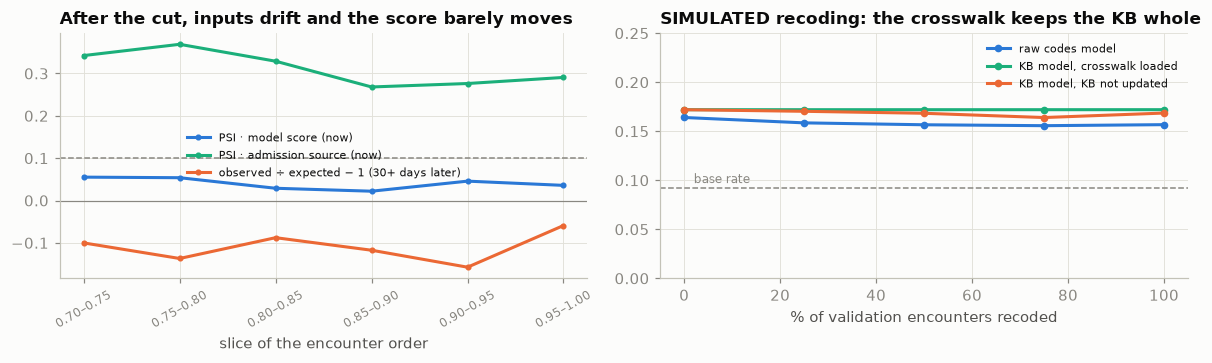

In [15]:
# (c) SIMULATION — a coding change through the ontology. The US moved from ICD-9-CM to ICD-10-CM on 1 October 2015,
# after this data ends. We invent ICD-10-style codes (real chapter letters, made-up numbers) and recode a growing share
# of holdout encounters. Nothing below is real ICD-10 data, and the crosswalk is perfect by construction.
ICD10_LETTER = {"infectious": "A", "neoplasms": "C", "endocrine": "E", "blood": "D", "mental": "F", "nervous": "G",
                "circulatory": "I", "respiratory": "J", "digestive": "K", "genitourinary": "N", "pregnancy": "O", "skin": "L",
                "musculoskeletal": "M", "congenital": "Q", "perinatal": "P", "symptoms": "R", "injury": "S", "V": "Z", "E": "W"}
def fake_icd10(code9: str) -> str:
    h = int(hashlib.md5(code9.encode()).hexdigest(), 16)
    return f"{ICD10_LETTER[chapter_of(code9)]}{h % 100:02d}.{h // 100 % 10}"

crosswalk = {fake_icd10(c): c for c in codes}                     # the GEM-like table a coding team would load into the KB
RAW_CODED, KB_CODED = "after coding + raw codes", "after coding + knowledge base"
recode_order = rng.permutation(va.sum())
D = df.loc[va].reset_index(drop=True)                     # validation window: the holdout stays a one-time report
rows_sim = []
for share in [0, 0.25, 0.5, 0.75, 1.0]:
    Ds = D.copy()
    hit = np.zeros(len(Ds), bool); hit[recode_order[:int(share * len(Ds))]] = True
    for i in (1, 2, 3):
        new = Ds[f"code_{i}"].where(~hit | Ds[f"code_{i}"].isna(), Ds[f"code_{i}"].map(lambda c: fake_icd10(c) if isinstance(c, str) else c))
        Ds[f"diag_{i}"] = np.where(hit & Ds[f"code_{i}"].notna(), new, Ds[f"diag_{i}"])       # raw model sees the new strings
        Ds[f"code_{i}"] = new
    stale = build_features(Ds)                                                                   # KB not updated: new codes unmapped
    fresh = build_features(Ds.assign(**{f"code_{i}": Ds[f"code_{i}"].map(lambda c: crosswalk.get(c, c) if isinstance(c, str) else c)
                                        for i in (1, 2, 3)}))                                    # KB with the crosswalk loaded
    # LightGBM maps categories it never saw in training to 'missing'
    rows_sim.append({"share recoded": share,
                     "raw codes model": average_precision_score(y_va, models[RAW_CODED].predict_proba(stale[LADDER[RAW_CODED]])[:, 1]),
                     "KB model, crosswalk loaded": average_precision_score(y_va, models[KB_CODED].predict_proba(fresh[LADDER[KB_CODED]])[:, 1]),
                     "KB model, KB not updated": average_precision_score(y_va, models[KB_CODED].predict_proba(stale[LADDER[KB_CODED]])[:, 1]),
                     "unmapped codes": (stale.chapter_1.astype(str) == "missing").mean() - (D.code_1.isna()).mean(),
                     "PSI primary chapter": psi_cat(X.loc[tr, "chapter_1"].astype(str), stale.chapter_1.astype(str))})
sim = pd.DataFrame(rows_sim).set_index("share recoded")
# the SHACL gate on the day the new codes arrive before the crosswalk does
stale_kb = Graph() + kb
for c in sorted({fake_icd10(c) for c in pd.concat([D.code_1, D.code_2, D.code_3]).dropna()}):
    stale_kb.add((RD[f"code/{c}"], RDF.type, RD.Code)); stale_kb.add((RD[f"code/{c}"], RD.notation, Literal(c)))
print("SHACL with the new codes loaded but no crosswalk:"); print(shacl_violations(stale_kb).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
t_ = np.arange(len(monitor))
ax.plot(t_, monitor["PSI score"], "-o", ms=3, lw=2, color=SERIES[0], label="PSI · model score (now)")
ax.plot(t_, monitor["PSI admission source"], "-o", ms=3, lw=2, color=SERIES[2], label="PSI · admission source (now)")
ax.plot(t_, monitor["observed ÷ expected"] - 1, "-o", ms=3, lw=2, color=SERIES[1], label="observed ÷ expected − 1 (30+ days later)")
ax.axhline(0.10, color=MUTED, ls="--", lw=1); ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xticks(t_); ax.set_xticklabels(monitor.index, rotation=30, fontsize=8)
ax.set_title("After the cut, inputs drift and the score barely moves"); ax.set_xlabel("slice of the encounter order"); ax.legend(fontsize=7.5)
ax = axes[1]
for col, c in [("raw codes model", SERIES[0]), ("KB model, crosswalk loaded", SERIES[2]), ("KB model, KB not updated", SERIES[1])]:
    ax.plot(sim.index * 100, sim[col], "-o", ms=4, lw=2, color=c, label=col)
ax.axhline(y_va.mean(), color=MUTED, ls="--", lw=1); ax.text(2, y_va.mean() * 1.05, "base rate", color=MUTED, fontsize=8)
ax.set_ylim(0, 0.25); ax.set_title("SIMULATED recoding: the crosswalk keeps the KB whole"); ax.set_xlabel("% of validation encounters recoded")
ax.legend(fontsize=7.5)
plt.tight_layout()
display(sim.rename(index=lambda v: f"{v:.0%}").style.format({"raw codes model": "{:.3f}", "KB model, crosswalk loaded": "{:.3f}", "KB model, KB not updated": "{:.3f}",
                          "unmapped codes": "{:.1%}", "PSI primary chapter": "{:.2f}"}))

**The population moves; the ranking holds.** Emergency admissions are 51 % of training, 64 % of the holdout; AUPRC is 0.15–0.16 for the three main sources, all over-predicted (observed ÷ expected 0.83–0.94). By-source score PSI is already 0.06–0.28 on validation and 0.10–0.18 on the holdout, so a by-source alert at 0.10 would fire on noise: alert on the overall score PSI (0.03 validation, 0.06 holdout).

**Inputs shout, the score whispers.** After the cut, specialty and admission source pass the 0.25 PSI alarm (0.60–0.85, 0.27–0.37) through recording habits, while score PSI stays at 0.02–0.06 and precision at capacity at 22–25 %. Alert on the score and the call queue.

**A coding change is a knowledge-base event.** Recoding costs the raw-code model 0.164 → 0.157. With the crosswalk the KB model is unchanged (0.172) by construction; without it, 0.164–0.170. The signals are immediate: unmapped codes track the switch, primary-chapter PSI rises from 0.02 to 19.8, SHACL rejects all 665 new codes. The at-discharge champion uses no codes and does not notice.

**What a real deployment monitors.** *Now*: overall score PSI, calls against the quota, unmapped codes, SHACL failures, who is called. *Later* (30 days plus the coding lag): precision at capacity, observed ÷ expected, miss rates by group. Retrain quarterly on matured labels, or early on score PSI above 0.10 or a crosswalk change; roll back via the registry alias.

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The nine rows from the project card, updated with what this notebook found. Thresholds are placeholders for the business.

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/readmit/` (as-of features, normaliser, KB); `POST /risk` at discharge returns score, rank and packet; Postgres holds the worklist. |
| Monitoring (S04) | Section 7's list: overall score PSI (alert at 0.10), the queue, unmapped codes, SHACL; by-source PSI (0.06–0.28 on validation) only as a diagnostic. |
| CI/CD gate (S05) | Frozen holdout (10,781 new-patient discharges, SHA-256 `86c7d8ac…`): precision at 12.8 % capacity ≥ 15 % (16.5 %), AUPRC ≥ 0.14 (0.153), observed ÷ expected 0.8–1.2 (0.85), sex miss-rate gap ≤ 10 points (5.8). |
| MLflow tracking and registry (S06) | KB and normaliser versions, SHACL report, exclusion rule, cut points, data and holdout SHA-256, fairness slices; `champion` = at discharge, `challenger` = after coding + KB. |
| Offline / online training and serving | Online at discharge into a weekly quota; quarterly retraining on matured labels, early on drift or a KB change. |
| Data and model drift | Real: recording along the order (payer unknown 100 % → 13.8 %, specialty unknown 36 % → 68 %), admission mix (emergency 51 % → 64 %). Simulated: ICD-10 recoding, coded KB model 0.172 → 0.164–0.170 without crosswalk. Label delay: 30 days plus coding. |
| Knowledge base and context (S07–S09) | 5,703 triples: 915 codes, 881 categories, 19 chapters, 9 groups, 34 diabetes codes, 6 drug classes; SHACL flags 43 malformed raw codes, 2 unclassified drugs. Ablation (validation): medication classes +0.003, coded KB +0.009, KB over raw codes +0.009; none clearly above zero. |
| GenAI and context engineering (S10–S11) | Nurse's call script from the grounding packet, no clinical advice; golden set, injection tests. |
| Governance | Health data (GDPR Art. 9), de-identified; possibly a medical device (MDR Rule 11), then AI Act high-risk (Art. 6(1)); decision support only; protected attributes only in the fairness check; CC0 / CC BY 4.0. |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S2**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap, with a test each.** As-of history, a test that every scored feature exists at discharge, the death and hospice rule from the mapping file, explicit `?` and `None`, codes checked by SHACL; and the ADR for `encounter_id` as an ordering proxy, with what it cannot tell you.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `CALLS_PER_WEEK` (10–60), `CALL_EFFECT` (0–20 %) and both costs; choose quota or threshold, and who is eligible (a transfer to an inpatient facility is not a phone call); write the ADR and who signed it off.
- **C4 — Package and gate (Sessions 02, 03, 05).** `src/readmit/`, a container serving `POST /risk`, and `make ci` that rebuilds the KB, runs SHACL and gates precision at capacity, calibration and the fairness gap on the frozen holdout, refusing a changed fingerprint.
- **C5 — Register, document, monitor (Sessions 04, 06).** MLflow runs with the KB version; `champion` and `challenger` aliases; a model card; a monitoring plan with Section 7's signals, the label delay and the retraining trigger.

### Extension

- **E1 — The knowledge-base ablation (Sessions 07–09).** Add competency questions (Charlson or Elixhauser comorbidities) and a version; measure with and without KB context on validation, under recoding and for S2.
- **E2 — Is the risk a probability?** Check the given model's calibration on validation by admission source and group (no refitting), and redo the value table only if the cost model assumes a probability; say which.
- **E3 — Fairness for a regulator.** Race × sex and three capacities; should miss rates be equalised, at what cost in reach? Write the two sentences a regulator would read.
- **E4 — Regulatory position.** Medical device under MDR Rule 11 or not (MDCG 2019-11)? If so, what does AI Act high risk ask of the deployer? Which GDPR Art. 9 condition applies?

### Stretch

- **S1 — Online serving and its cost.** ADT event → as-of history → score → worklist: latency, late codes, cost per thousand discharges (Session 11).
- **S2 — The discharge-call script (Sessions 10–11).** An LLM drafts it from the packet: structured output, versioned prompt, no clinical advice; a golden set of 30 packets with required and forbidden content; evaluate factuality, advice and tone; injection tests; cost per script.
- **S3 — The coding change, for real.** Load the CMS ICD-10-CM → ICD-9-CM General Equivalence Mappings into the KB, handle one-to-many entries, rerun Section 7(c).

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Session 02 layout; fresh-clone test passes; `data/` not committed
- [ ] `README.md`: cut points, exclusion rule, capacity constants, data access (`IDs_mapping.csv` from UCI)
- [ ] Grouped, ordered evaluation; each trap fixed with a test; ADRs for the ordering proxy and the operating point
- [ ] Fairness check with bootstrap intervals; knowledge base with SHACL in CI, and the ablation
- [ ] `make ci` with precision-at-capacity, calibration and fairness gates; registered model, model card, monitoring plan
- [ ] One-page recommendation for the care-coordination lead (reach, assumptions, who is missed, regulatory position)
- [ ] Required tasks done: C1–C5, E1–E4 and S2
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `scikit-learn`, `lightgbm`, `matplotlib`, `rdflib`, `pyshacl`, `kagglehub` (pinned in `requirements.txt`).
- Strack, B. et al. (2014). *Impact of HbA1c Measurement on Hospital Readmission Rates.* BioMed Research International, 781670; data at UCI, doi:10.24432/C5230J.
- Kansagara, D. et al. (2011). *Risk Prediction Models for Hospital Readmission: A Systematic Review.* JAMA 306(15).
- Nissen, S. E., Wolski, K. (2007). *Effect of Rosiglitazone on the Risk of Myocardial Infarction and Death from Cardiovascular Causes.* NEJM. CDC/NCHS, *ICD-9-CM Tabular List*; CMS, *ICD-10-CM GEMs*; W3C, *SHACL*.
- GDPR Art. 9; MDR (EU) 2017/745, Annex VIII Rule 11; MDCG 2019-11; AI Act (EU) 2024/1689, Art. 6 and Annex I.

In [16]:
print(f"pandas {pd.__version__} · numpy {np.__version__} · scikit-learn {sklearn.__version__} · lightgbm {lgb.__version__} · "
      f"rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

pandas 3.1.0 · numpy 2.5.4 · scikit-learn 1.9.1 · lightgbm 4.7.0 · rdflib 7.6.0 · pyshacl 0.40.1
notebook finished · total wall time 73s
